In [1]:
import ee   
ee.Initialize(project='mlprojects-510908')
#This is to initialise the google earth engine

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [2]:
lst = (ee.ImageCollection('MODIS/061/MOD11A2')
         .filterDate('2022-07-01', '2022-08-01')
         .select('LST_Day_1km'))

print(lst.size().getInfo())
print(lst.first().getInfo())

4
{'type': 'Image', 'bands': [{'id': 'LST_Day_1km', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 65535}, 'dimensions': [43200, 21600], 'crs': 'SR-ORG:6974', 'crs_transform': [926.6254331383326, 0, -20015109.355797, 0, -926.6254331391667, 10007554.677903]}], 'version': 1779675982326072, 'id': 'MODIS/061/MOD11A2/2022_07_04', 'properties': {'system:time_start': 1656892800000, 'google:max_source_file_timestamp': 1657873414000, 'num_tiles': 317, 'system:footprint': {'type': 'LinearRing', 'coordinates': [[-180, -90], [180, -90], [180, 90], [-180, 90], [-180, -90]]}, 'system:time_end': 1657584000000, 'system:asset_size': 984801986, 'system:index': '2022_07_04'}}


In [3]:
# Load the Country borders table hosted on Earth Engine
countries = ee.FeatureCollection('USDOS/LSIB_SIMPLE/2017')
uk = countries.filter(ee.Filter.eq('country_na', 'United Kingdom'))
#Ask how many rows matched? Should just be one.
print(uk.size().getInfo())

#ask the server for the shapes bounding box
print(uk.geometry().bounds().getInfo())

1
{'geodesic': False, 'type': 'Polygon', 'coordinates': [[[-13.690860748704889, 49.902084326114], [1.7658056360502927, 49.902084326114], [1.7658056360502927, 60.847084071722314], [-13.690860748704889, 60.847084071722314], [-13.690860748704889, 49.902084326114]]]}


In [4]:
# Draw 2000 random locations that fall inside the uk polygon
#seed=42 makes the draw repeatable, so tou get the same points every time

points = ee.FeatureCollection.randomPoints(
    region=uk.geometry(),
    points= 2000,
    seed=42
)

#count them to confirm we got what we asked for 
print(points.size().getInfo())
print(points.first().getInfo())

2000
{'type': 'Feature', 'geometry': {'type': 'Point', 'coordinates': [0.11948981352419201, 50.94608390049139]}, 'id': '0', 'properties': {}}


In [5]:
import geemap                     # interactive maps for Earth Engine
import pandas as pd               # tables
import numpy as np                # numbers, and np.nan for missing values
import matplotlib.pyplot as plt   # plots


In [6]:
lst_mean = lst.mean()
lst_c = lst_mean.multiply(0.02).subtract(273.15)
lst_uk= lst_c.clip(uk)
vis = {'min': 10, 'max': 35, 'palette': ['blue', 'cyan', 'orange', 'red']}
m = geemap.Map()
m.centerObject(uk, 5) #zoom into the uk
m.addLayer(lst_uk, vis, 'Mean LST July 2022 (C)') #temperature layer
m.addLayer(points, {'color': 'black'}, 'Sample Points') #my 2000 points
m

Map(center=[54.0257825222589, -2.779718210465655], controls=(WidgetControl(options=['position', 'transparent_b…

In [7]:
valid = lst.count()
vis_n = {'min': '0', 'max': 4, 'palette': ['white', 'yellow', 'green']}
m.addLayer(valid.clip(uk), vis_n, 'Valid images (count)')
m

Map(center=[54.0257825222589, -2.779718210465655], controls=(WidgetControl(options=['position', 'transparent_b…

In [8]:
times = lst.aggregate_array('system:time_start').getInfo() # ask the server for each image's start time (milliseconds since 1970)
print([pd.to_datetime(t, unit='ms').date() for t in times]) # convert each to a readable date and print the list


[datetime.date(2022, 7, 4), datetime.date(2022, 7, 12), datetime.date(2022, 7, 20), datetime.date(2022, 7, 28)]


In [9]:
dec = ee.ImageCollection('MODIS/061/MOD11A2').filterDate('2021-12-01', '2022-01-10')
t = dec.aggregate_array('system:time_start').getInfo()
print([pd.to_datetime(x, unit='ms').date() for x in t])

[datetime.date(2021, 12, 3), datetime.date(2021, 12, 11), datetime.date(2021, 12, 19), datetime.date(2021, 12, 27), datetime.date(2022, 1, 1), datetime.date(2022, 1, 9)]


In [10]:
ndvi = (ee.ImageCollection('MODIS/061/MOD13A2')
                           .filterDate('2022-06-01', '2022-08-31')
                           .select('NDVI'))
tn = ndvi.aggregate_array('system:time_start').getInfo()
print([pd.to_datetime(x, unit='ms').date() for x in tn])

[datetime.date(2022, 6, 10), datetime.date(2022, 6, 26), datetime.date(2022, 7, 12), datetime.date(2022, 7, 28), datetime.date(2022, 8, 13), datetime.date(2022, 8, 29)]


In [11]:
sample = lst_c.sampleRegions(
    collection = points,
    scale = 1000,
    geometries = True
)
print(sample.size().getInfo())
print(sample.first().getInfo())

1983
{'type': 'Feature', 'geometry': {'geodesic': False, 'type': 'Point', 'coordinates': [0.12127256335613541, 50.947951338838664]}, 'id': '0_0', 'properties': {'LST_Day_1km': 28.44500000000005}}


In [12]:
points = points.map(lambda f: f.set({
    'pid': f.id(),
    'lon': f.geometry().coordinates().get(0),
    'lat': f.geometry().coordinates().get(1)
}))

# Sample the July mean LST at the points again; now each row carries pid, lon and lat
sample = lst_c.sampleRegions(collection=points, scale=1000)

# Bring the table to your laptop as a pandas DataFrame (about 2000 rows, so getInfo-sized is fine)
features = sample.getInfo()['features']
df = pd.DataFrame([f['properties'] for f in features])

print(df.shape)
print(df.head())
print(df['LST_Day_1km'].describe())



(1983, 4)
   LST_Day_1km        lat       lon pid
0    28.445000  50.946084  0.119490   0
1    32.043333  52.117576 -1.990680   1
2    22.735000  57.234761 -3.185914   2
3    21.723333  51.976955 -4.529788   3
4    23.936667  56.580776 -2.628107   4
count    1983.000000
mean       25.080930
std         5.178121
min         8.576667
25%        21.024167
50%        24.996667
75%        29.432500
max        39.200000
Name: LST_Day_1km, dtype: float64


In [13]:
print(df.nlargest(5, 'LST_Day_1km'))
print(df.nsmallest(5, 'LST_Day_1km'))

      LST_Day_1km        lat       lon   pid
1799    39.200000  52.130731 -0.454060  1816
1593    37.923333  52.650348  1.281582  1609
885     36.995000  51.510241 -0.373738   897
1875    36.610000  51.527442  0.145772  1892
625     36.370000  51.510318 -0.584849   632
      LST_Day_1km        lat       lon   pid
1583     8.576667  57.379031 -5.694786  1599
181      9.765000  58.997774 -3.162344   182
879     11.660000  57.832656 -7.027187   891
116     12.365000  60.715273 -0.958504   117
1547    12.476667  58.963958 -2.732235  1562


In [14]:
summer22 = (ee.ImageCollection('MODIS/061/MOD11A2')
            .filterDate('2022-06-01', '2022-09-01')
            .select('LST_Day_1km'))

print(summer22.size().getInfo())
t = summer22.aggregate_array('system:time_start').getInfo()
print([pd.to_datetime(x, unit='ms').date() for x in t])

12
[datetime.date(2022, 6, 2), datetime.date(2022, 6, 10), datetime.date(2022, 6, 18), datetime.date(2022, 6, 26), datetime.date(2022, 7, 4), datetime.date(2022, 7, 12), datetime.date(2022, 7, 20), datetime.date(2022, 7, 28), datetime.date(2022, 8, 5), datetime.date(2022, 8, 13), datetime.date(2022, 8, 21), datetime.date(2022, 8, 29)]


In [15]:
MODIS_SCALE = 926.6254331383326                        # MODIS's native pixel size in metres; always sample MODIS at this, never at a rounded 1000

points_sub = points.limit(200)                         # the first 200 points, a small test subset

def sample_one(img):                                   # function applied to ONE composite; Earth Engine runs it on the server
    date = img.date().format('YYYY-MM-dd')             # this composite's start date, as text
    celsius = img.multiply(0.02).subtract(273.15)      # raw integers to degrees Celsius
    celsius = celsius.unmask(-9999)                    # fill masked pixels with -9999, so every point returns a row
    rows = celsius.sampleRegions(collection = points_sub, scale = MODIS_SCALE)   # read the value at each point, on MODIS's own pixel grid
    return rows.map(lambda f: f.set('date', date))     # stamp every row with the composite's date

# Apply it to every composite; the result is 12 small tables, and flatten() stacks them into one
table = ee.FeatureCollection(summer22.map(sample_one)).flatten()

print(table.size().getInfo())                          # total rows; expect exactly 2400 (200 x 12)
rows = table.getInfo()['features']                     # bring the rows to your laptop
df22 = pd.DataFrame([f['properties'] for f in rows])   # build a table from each row's properties
df22['LST_Day_1km'] = df22['LST_Day_1km'].replace(-9999, np.nan)   # turn the placeholder into a real missing value, so rerunning this cell alone is safe
print(df22.shape)                                      # expect (2400, 5)


2400
(2400, 5)


In [16]:
df22['LST_Day_1km'] = df22['LST_Day_1km'].replace(-9999, np.nan)
print(df22['LST_Day_1km'].isna().sum())   
print(df22['LST_Day_1km'].isna().groupby(df22['date']).sum())
print(df22['LST_Day_1km'].describe())  
print(df22.head())


319
date
2022-06-02     26
2022-06-10     26
2022-06-18      3
2022-06-26     61
2022-07-04      5
2022-07-12      5
2022-07-20    116
2022-07-28     22
2022-08-05      6
2022-08-13      4
2022-08-21     18
2022-08-29     27
Name: LST_Day_1km, dtype: int64
count    2081.000000
mean       23.886079
std         5.858903
min         2.690000
25%        19.630000
50%        23.390000
75%        27.870000
max        39.770000
Name: LST_Day_1km, dtype: float64
   LST_Day_1km        date        lat       lon pid
0        25.03  2022-06-02  50.946084  0.119490   0
1          NaN  2022-06-02  52.117576 -1.990680   1
2        23.09  2022-06-02  57.234761 -3.185914   2
3        18.71  2022-06-02  51.976955 -4.529788   3
4        22.59  2022-06-02  56.580776 -2.628107   4


In [17]:
era = ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')   # ERA5-Land daily weather, pixels about 11 km wide
ERA_PROJ = era.first().projection()                      # ERA5-Land's native grid; averaging days loses it, so we restore it later
ERA_SCALE = 11131.949079327358                           # ERA5-Land's native pixel size in metres

t = ee.Date('2022-07-04')
win = era.filterDate(t.advance(-8, 'day'), t)

print(win.size().getInfo())
d = win.aggregate_array('system:time_start').getInfo()
print([pd.to_datetime(x, unit = 'ms').date() for x in d])


8
[datetime.date(2022, 6, 26), datetime.date(2022, 6, 27), datetime.date(2022, 6, 28), datetime.date(2022, 6, 29), datetime.date(2022, 6, 30), datetime.date(2022, 7, 1), datetime.date(2022, 7, 2), datetime.date(2022, 7, 3)]


In [18]:
sm = (win.select('volumetric_soil_water_layer_1')
      .mean()
      .setDefaultProjection(ERA_PROJ)    # restore ERA5's native grid, which .mean() throws away
      .unmask(-9999))

sm_rows = sm.sampleRegions(collection=points, scale = ERA_SCALE)   # sample on ERA5's own pixel grid
sm_df = pd.DataFrame([f['properties'] for f in sm_rows.getInfo()['features']])
sm_df = sm_df.replace(-9999, np.nan)

print(sm_df.shape)
print(sm_df['volumetric_soil_water_layer_1'].describe())
print(sm_df['volumetric_soil_water_layer_1'].nunique())


(2000, 4)
count    1903.000000
mean        0.342271
std         0.122181
min         0.111414
25%         0.265792
50%         0.323246
75%         0.374772
max         0.730778
Name: volumetric_soil_water_layer_1, dtype: float64
1456


(200, 3)
                               LST_Day_1km  volumetric_soil_water_layer_1
LST_Day_1km                       1.000000                      -0.258921
volumetric_soil_water_layer_1    -0.258921                       1.000000


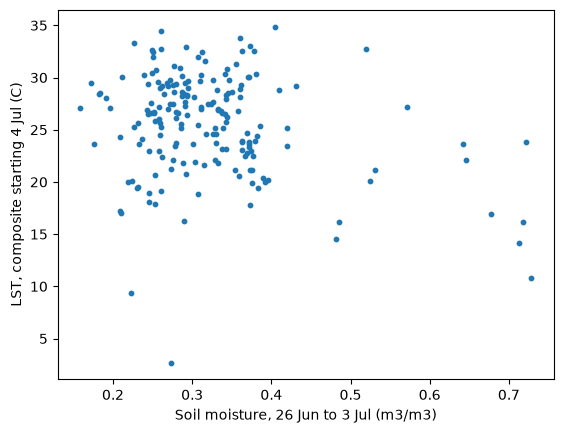

In [19]:
import matplotlib.pyplot as plt

lst_0704 = df22[df22['date'] == '2022-07-04'][['pid', 'LST_Day_1km']]
check = lst_0704.merge(sm_df[['pid', 'volumetric_soil_water_layer_1']], on= 'pid')
print(check.shape)
print(check.corr(numeric_only=True))

plt.scatter(check['volumetric_soil_water_layer_1'], check['LST_Day_1km'], s=10)
plt.xlabel('Soil moisture, 26 Jun to 3 Jul (m3/m3)')
plt.ylabel('LST, composite starting 4 Jul (C)')
plt.show()

In [20]:
def era_window(t):
    win = era.filterDate(t.advance(-8, 'day'), t)
    sm = win.select('volumetric_soil_water_layer_1').mean().rename('soil_moisture')
    precip = win.select('total_precipitation_sum').sum().rename('precip_8d')
    dew = win.select('dewpoint_temperature_2m').mean().rename('dewpoint')
    rad = win.select('surface_solar_radiation_downwards_sum').sum().rename('solar_8d')
    return sm.addBands([precip, dew, rad]).setDefaultProjection(ERA_PROJ)   # restore ERA5's native grid so points read the right pixel

In [21]:
t = ee.Date('2022-07-04')
era_img = era_window(t).unmask(-9999)
rows = era_img.sampleRegions(collection=points, scale = ERA_SCALE)   # sample on ERA5's own pixel grid
era_df = pd.DataFrame([f['properties'] for f in rows.getInfo()['features']])
era_df = era_df.replace(-9999, np.nan)

print(era_df.shape)
print(era_df.describe().T)

(2000, 7)
                count          mean           std           min           25%  \
dewpoint       1903.0  2.827232e+02  6.427966e-01  2.799068e+02  2.823342e+02   
lat            2000.0  5.390391e+01  2.301990e+00  5.001101e+01  5.199996e+01   
lon            2000.0 -2.737305e+00  2.002142e+00 -8.087054e+00 -4.117703e+00   
precip_8d      1903.0  2.961797e-02  1.587139e-02  6.802424e-03  1.623689e-02   
soil_moisture  1903.0  3.422710e-01  1.221810e-01  1.114142e-01  2.657924e-01   
solar_8d       1903.0  1.435639e+08  1.393804e+07  1.137463e+08  1.335215e+08   

                        50%           75%           max  
dewpoint       2.827337e+02  2.831544e+02  2.846619e+02  
lat            5.336541e+01  5.570689e+01  6.082187e+01  
lon           -2.779736e+00 -1.286258e+00  1.720731e+00  
precip_8d      2.673417e-02  4.018239e-02  8.551128e-02  
soil_moisture  3.232458e-01  3.747723e-01  7.307777e-01  
solar_8d       1.463878e+08  1.518548e+08  1.886411e+08  


In [22]:
lst_all = ee.ImageCollection('MODIS/061/MOD11A2').select('LST_Day_1km')
ndvi_all = ee.ImageCollection('MODIS/061/MOD13A2').select('NDVI') 

def sat_lags(t):
    prev = ee.Image(lst_all.filterDate(t.advance(-8, 'day'), t).first())
    lst_prev = prev.multiply(0.02).subtract(273.15).rename('lst_prev')
    nd = ee.Image(ndvi_all
                  .filterDate(t.advance(-60, 'day'), t.advance(-15, 'day'))
                  .sort('system:time_start', False)
                  .first())

    ndvi_lag = nd.multiply(0.0001).rename('ndvi_lag')
    return lst_prev.addBands(ndvi_lag)

In [23]:
for d in ['2022-07-04', '2022-07-12']:
    t = ee.Date(d)
    prev = prev = ee.Image(lst_all.filterDate(t.advance(-8, 'day'), t).first())
    nd = ee.Image(ndvi_all.filterDate(t.advance(-60, 'day'), t.advance(-15, 'day')).sort('system:time_start', False).first())
    print(d, 'prev LST starts', prev.date().format('YYYY-MM-dd').getInfo(), '| NDVI starts', nd.date().format('YYYY-MM-dd').getInfo())

2022-07-04 prev LST starts 2022-06-26 | NDVI starts 2022-06-10
2022-07-12 prev LST starts 2022-07-04 | NDVI starts 2022-06-26


In [24]:
t = ee.Date('2022-07-04')                                        # target composite start
sat_img = sat_lags(t).unmask(-9999)                              # build the 2-band image; fill masked pixels with the placeholder
rows = sat_img.sampleRegions(collection=points, scale=MODIS_SCALE)   # read both bands at the 2000 points, on MODIS's own pixel grid
sat_df = pd.DataFrame([f['properties'] for f in rows.getInfo()['features']]).replace(-9999, np.nan)   # table, placeholder to NaN
print(sat_df.shape)                                              # expect (2000, 5)
print(sat_df.describe().T)                                       # one line of statistics per column

(2000, 5)
           count       mean       std        min        25%        50%  \
lat       2000.0  53.903907  2.301990  50.011007  51.999960  53.365407   
lon       2000.0  -2.737305  2.002142  -8.087054  -4.117703  -2.779736   
lst_prev  1306.0  18.767305  3.646150   5.210000  16.225000  18.960000   
ndvi_lag  1991.0   0.741340  0.105334  -0.137900   0.701950   0.760600   

                75%        max  
lat       55.706890  60.821874  
lon       -1.286258   1.720731  
lst_prev  21.210000  30.030000  
ndvi_lag   0.807750   0.915800  


In [25]:
prev_check = df22[df22['date'] == '2022-06-26'][['pid', 'LST_Day_1km']]   # LST of the 26 Jun composite, from the earlier table (200 points)
cmp = prev_check.merge(sat_df[['pid', 'lst_prev']], on='pid')               # attach lst_prev for the same points
print(cmp.shape)                                                            # expect (200, 3)
print(cmp['LST_Day_1km'].isna().sum(), cmp['lst_prev'].isna().sum())        # missing in each; the two numbers should be equal (about 65)
print((cmp['LST_Day_1km'] - cmp['lst_prev']).abs().max())                   # largest difference between the two; expect 0 or about 0.01


(200, 3)
61 61
0.0


In [26]:
dem = (ee.ImageCollection('COPERNICUS/DEM/GLO30') 
       .select('DEM')
       .mosaic()
       .rename('elevation'))

zones = points_sub.map(lambda f: f.buffer(500))

elev = dem.reduceRegions(collection=zones, reducer = ee.Reducer.mean(),
                         scale=30)

elev_df = pd.DataFrame([f['properties'] for f in elev.getInfo()['features']])
print(elev_df.shape)
print(elev_df['mean'].describe())

(200, 4)
count    200.000000
mean     164.494772
std      158.486669
min       -1.337339
25%       58.910787
50%      107.245739
75%      230.512289
max      794.751150
Name: mean, dtype: float64


In [27]:
lc = ee.Image(ee.ImageCollection('ESA/WorldCover/v200').first()).select('Map')

classes = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]   # the 11 WorldCover class codes (tree, shrub, grass, crop, built-up, bare, snow, water, wetland, mangrove, moss

onehot = ee.Image.cat([lc.eq(c).rename(f'lc{c}') for c in classes])   # 11 bands; band lc40 is 1 where the pixel is class 40 (cropland) and 0 elsewhere

fractions = onehot.reduceRegions(collection=zones,       # for each circle...
                                 reducer=ee.Reducer.mean(),   # ...the mean of a 0/1 band IS the fraction of the circle in that class
                                 scale=10)               # at the land cover's own 10 m resolution

lc_df = pd.DataFrame([f['properties'] for f in fractions.getInfo()['features']])   # table from each row's properties
print(lc_df.shape)                                       # expect (200, 14): 11 classes plus pid, lon, lat
print(lc_df.drop(columns=['pid', 'lon', 'lat']).sum(axis=1).describe())   # each row's fractions added up; should be about 1
print(lc_df.drop(columns=['pid', 'lon', 'lat']).mean().round(3))          # average fraction of each class across the 200 points

(200, 14)
count    2.000000e+02
mean     1.000000e+00
std      5.424706e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64
lc10     0.206
lc100    0.000
lc20     0.000
lc30     0.552
lc40     0.186
lc50     0.037
lc60     0.000
lc70     0.000
lc80     0.017
lc90     0.001
lc95     0.000
dtype: float64


In [28]:
target = (df22[df22['date'] == '2022-07-04'][['pid', 'lon', 'lat', 'date', 'LST_Day_1km']]   # the 4 July target rows, with the columns we keep
          .rename(columns={'LST_Day_1km': 'lst_target'}))                                     # clearer name: this is what we predict

era_cols = era_df.drop(columns=['lon', 'lat'])                          # drop lon/lat so they are not duplicated when merging
sat_cols = sat_df.drop(columns=['lon', 'lat'])                          # same for the satellite predictors
elev_cols = elev_df.drop(columns=['lon', 'lat']).rename(columns={'mean': 'elevation'})   # same, and give the column a meaningful name
lc_cols = lc_df.drop(columns=['lon', 'lat'])                            # same for the land cover fractions

table = (target
         .merge(era_cols,  on='pid', how='left', validate='one_to_one')   # attach weather predictors, matching on pid
         .merge(sat_cols,  on='pid', how='left', validate='one_to_one')   # attach previous LST and NDVI
         .merge(elev_cols, on='pid', how='left', validate='one_to_one')   # attach elevation
         .merge(lc_cols,   on='pid', how='left', validate='one_to_one'))  # attach land cover fractions

table['doy'] = pd.to_datetime(table['date']).dt.dayofyear               # day of the year of the target start (1 January = 1)

print(table.shape)                                                      # rows and columns
print(table.isna().sum())                                               # missing values in each column


(200, 24)
pid               0
lon               0
lat               0
date              0
lst_target        5
dewpoint         10
precip_8d        10
soil_moisture    10
solar_8d         10
lst_prev         61
ndvi_lag          0
elevation         0
lc10              0
lc100             0
lc20              0
lc30              0
lc40              0
lc50              0
lc60              0
lc70              0
lc80              0
lc90              0
lc95              0
doy               0
dtype: int64


In [29]:
points_in = points_sub                                       # points the functions sample; the 200 test points for now

# MODIS bands (target, previous LST, NDVI) share one grid, so they are sampled together on MODIS's native pixels
def rows_modis(img):                                         # img is ONE target composite (8-day LST)
    t = img.date()                                           # start date of this composite
    target = img.multiply(0.02).subtract(273.15).rename('lst_target')   # what we predict, in Celsius
    stack = target.addBands(sat_lags(t)).unmask(-9999)       # add previous LST and NDVI; fill masked pixels with the placeholder
    rows = stack.sampleRegions(collection=points_in, scale=MODIS_SCALE)   # read the 3 bands at the points on MODIS's own grid
    return rows.map(lambda f: f.set('date', t.format('YYYY-MM-dd')))     # stamp each row with the date

# ERA5 bands live on a different (coarser) grid, so they are sampled separately on ERA5's native pixels
def rows_era(img):                                           # img is the same target composite; we only use its date
    t = img.date()                                           # start date of the target
    rows = era_window(t).unmask(-9999).sampleRegions(collection=points_in, scale=ERA_SCALE)   # 4 weather columns on ERA5's grid
    return rows.map(lambda f: f.set('date', t.format('YYYY-MM-dd')))     # stamp each row with the date

one = ee.Image(lst_all.filterDate('2022-07-04', '2022-07-05').first())   # the single composite that starts on 4 July
mod_df = pd.DataFrame([f['properties'] for f in rows_modis(one).getInfo()['features']]).replace(-9999, np.nan)
era_test = pd.DataFrame([f['properties'] for f in rows_era(one).getInfo()['features']]).replace(-9999, np.nan)
print(mod_df.shape, era_test.shape)                          # expect (200, 7) and (200, 8)

test_df = mod_df.merge(era_test.drop(columns=['lon', 'lat']), on=['pid', 'date'], validate='one_to_one')   # join the two grids by point and date
cmpt = table.merge(test_df, on='pid', suffixes=('_old', '_new'))   # line up the one-date table and the new functions by pid
for c in ['lst_target', 'soil_moisture', 'precip_8d', 'dewpoint', 'solar_8d', 'lst_prev', 'ndvi_lag']:
    print(c, (cmpt[c + '_old'] - cmpt[c + '_new']).abs().max())    # the largest difference per column; 0 means identical


(200, 7) (200, 8)
lst_target 0.0
soil_moisture 0.0
precip_8d 0.0
dewpoint 0.0
solar_8d 0.0
lst_prev 0.0
ndvi_lag 0.0


In [30]:
targets = (lst_all
            .filter(ee.Filter.calendarRange(2003, 2023, 'year'))
            .filter(ee.Filter.calendarRange(6, 8, 'month')))

print(targets.size().getInfo())
stamps = targets.aggregate_array('system:time_start').getInfo()
per_year = pd.Series([pd.to_datetime(x, unit = 'ms').year for x in stamps]).value_counts().sort_index()
print(per_year)

252
2003    12
2004    12
2005    12
2006    12
2007    12
2008    12
2009    12
2010    12
2011    12
2012    12
2013    12
2014    12
2015    12
2016    12
2017    12
2018    12
2019    12
2020    12
2021    12
2022    12
2023    12
Name: count, dtype: int64


In [31]:
points_in = points

t22 = targets.filter(ee.Filter.calendarRange(2022, 2022, 'year'))
modis_22 = ee.FeatureCollection(t22.map(rows_modis)).flatten()

task = ee.batch.Export.table.toDrive(                           # describe an export job: results go to Google Drive
    collection=modis_22,                                        # the table to export
    description='modis_features_2022',                          # the task's name, shown in the task list
    folder='ml2_exports',                                       # Drive folder to put the file in
    fileNamePrefix='modis_features_2022',                       # the CSV's file name
    fileFormat='CSV',                                           # plain text table
    selectors=['pid', 'date', 'lon', 'lat', 'lst_target', 'lst_prev', 'ndvi_lag']   # which columns to write, in this order
)
task.start()                                                    # send the job to Google; this returns at once
print(task.status())                                            # the first status line, probably READY

{'state': 'READY', 'description': 'modis_features_2022', 'priority': 100, 'creation_timestamp_ms': 1791540865420, 'update_timestamp_ms': 1791540865420, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_FEATURES', 'id': 'CHV6DJW5W2FCBA7RJEACDWV3', 'name': 'projects/mlprojects-510908/operations/CHV6DJW5W2FCBA7RJEACDWV3'}


In [32]:
print(task.status()['state'])                                   # READY, RUNNING, COMPLETED or FAILED

READY
